In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from datetime import datetime, timedelta
import os
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import re
from pathlib import Path
from scipy.stats import ks_2samp
from scipy.stats import wasserstein_distance
from properscoring import crps_ensemble
from scipy.spatial.distance import cdist
from scipy.stats import gaussian_kde

In [3]:
def crps_map_pointwise(forecast_da, obs_da):
    """
    forecast_da is IFS/Gencast forecasted temp: (latitude, longitude, number)
    obs_da is the ground truth:      (latitude, longitude) 
    returns:     (latitude, longitude)
    """
    forecast_da = forecast_da.transpose("latitude", "longitude", "number")
    obs_da = obs_da.transpose("latitude", "longitude")
    
    forecast_lon = forecast_da["longitude"]
    if forecast_lon.max() > 180:
        forecast_da = forecast_da.assign_coords({"longitude": ((forecast_lon + 180) % 360) - 180})
    forecast_da = forecast_da.sortby("longitude").sortby("latitude")
    obs_lon = obs_da["longitude"]
    if obs_lon.max() > 180:
        obs_da = obs_da.assign_coords({"longitude": ((obs_lon + 180) % 360) - 180}).sortby("longitude")
    obs_da = obs_da.sortby("longitude").sortby("latitude")

    forecast_da = forecast_da.sel(latitude=slice(*LAT_RANGE), longitude=slice(*LON_RANGE))
    obs_da = obs_da.sel(latitude=slice(*LAT_RANGE), longitude=slice(*LON_RANGE))

    # Align on common lat/lon grid
    obs_da, forecast_da = xr.align(obs_da, forecast_da, join="inner")

    nlat = obs_da.sizes["latitude"]
    nlon = obs_da.sizes["longitude"]
    nmem = forecast_da.sizes["number"]

    fcst = forecast_da.values.reshape(nlat * nlon, nmem)
    obs = obs_da.values.reshape(nlat * nlon)

    crps = np.empty(nlat * nlon, dtype=float)

    for i in range(nlat * nlon): #basically looping over each lat/long gridcell
        #out[i] = crps_ensemble(obs[i], fcst[i])
        ens_members = np.sort(fcst[i,:][np.isfinite(fcst[i,:])])
        if len(ens_members) == 0:
            crps[i]=np.nan
            continue
        total = 0.0
    
        #Pseudo code: crps[i] = SUM((F(y_k)^2)*(dy) for all functions smaller than the obs[i] value) + SUM ((F(y)-1)^2 for all values bigger than obs[i] value)*dy)
        for k in range(len(ens_members) - 1):
            y_k = ens_members[k]
            y_k1 = ens_members[k + 1]
            dy = y_k1 - y_k

            F_k = (k + 1) / len(ens_members) #+1 corrects for counting from zero

            if y_k1 <= obs[i]:
                # entire interval is below the observation
                total += (F_k ** 2) * dy
            elif y_k >= obs[i]:
                # entire interval is above the observation
                total += ((F_k - 1) ** 2) * dy
            else:
                # the observation splits this interval
                total += (F_k ** 2) * (obs[i] - y_k)
                total += ((F_k - 1) ** 2) * (y_k1 - obs[i])
        crps[i] = total
    print(crps.max(),crps.min())

    return xr.DataArray(
        crps.reshape(nlat, nlon),
        coords=obs_da.coords,
        dims=obs_da.dims,
        name="crps",
    )

In [4]:
# Helpers for datetime plots and loading in data
def combine_seed_ensembles(seed_paths):
    """
    Combine multiple GenCast seed files into a single ensemble
    along the 'sample' dimension.
    """
    datasets = []
    offset = 0

    for path in seed_paths:
        ds = xr.open_zarr(path)

        # remove trivial batch dimension
        if "batch" in ds.dims and ds.sizes["batch"] == 1:
            ds = ds.squeeze("batch")

        nmem = ds.sizes["sample"]

        # relabel members to avoid duplicates
        ds = ds.assign_coords(
            sample=np.arange(offset, offset + nmem)
        )

        datasets.append(ds)
        offset += nmem

    return xr.concat(datasets, dim="sample").sortby("sample")

def to_celsius(da):
    units = str(da.attrs.get("units", "")).lower()
    if units in ("k", "kelvin"):
        return da - 273.15
    return da

def lon_adjust(da, lat, lon):
    longitude_coords=da["longitude"]
    lon360 = float(longitude_coords.max()) > 180
    lon = lon % 360 if lon360 else lon
    return da.sel(latitude=lat, longitude=lon, method="nearest")

def closest_member(da, truth_val, time, ens_dim="number", label="ensemble"):
    da_t = da.sel(time=time, method="nearest").dropna(ens_dim)
    dist = np.abs(da_t - truth_val)
    idx = dist.argmin(dim=ens_dim)
    member = da_t.isel({ens_dim: int(idx.values)})

    print(
        f"{label}: closest = {float(member.values):.2f} °C, "
        f"truth = {float(truth_val):.2f} °C, "
        f"abs diff = {abs(float(member.values) - float(truth_val)):.2f} °C"
    )
    return member, dist

def coolest_member(da, time, ens_dim="number", label="ensemble"):
    da_t = da.sel(time=time, method="nearest").dropna(ens_dim)
    idx = da_t.argmin(dim=ens_dim)
    member = da_t.isel({ens_dim: int(idx.values)})

    print(f"{label}: coolest = {float(member.values):.2f} °C")
    return member

def crps_calculation(ensemble, truth):
    crps = 0.0
    ens_members = np.sort(ensemble[np.isfinite(ensemble)])
    if len(ens_members) == 0:
        crps=np.nan
    
    #Pseudo code: crps[i] = SUM((F(y_k)^2)*(dy) for all functions smaller than the obs[i] value) + SUM ((F(y)-1)^2 for all values bigger than obs[i] value)*dy)
    for k in range(len(ens_members) - 1):
            y_k = ens_members[k]
            y_k1 = ens_members[k + 1]
            dy = y_k1 - y_k

            F_k = (k + 1) / len(ens_members) #+1 corrects for counting from zero

            if y_k1 <= truth:
                # entire interval is below the observation
                crps += (F_k ** 2) * dy
            elif y_k >= truth:
                # entire interval is above the observation
                crps += ((F_k - 1) ** 2) * dy
            else:
                # the observation splits this interval
                crps += (F_k ** 2) * (truth - y_k)
                crps += ((F_k - 1) ** 2) * (y_k1 - truth)
    return crps

In [5]:
def load_nick_city_series(init_date):
    init_str = init_date.strftime("%Y-%m-%d")
    nick_paths = {
        "normal": f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_{init_str}.nc",
        "pi":     f"/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_{init_str}.nc",
        "incr":   f"/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_{init_str}.nc",
    }

    nick = {}
    for variant, path in nick_paths.items():
        ds = xr.open_dataset(path, engine="netcdf4")
        ds = ds.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                        if k in ds.coords or k in ds.dims})
        nick[variant] = ds

    nick_city = {}
    for variant in nick:
        nick_da = to_celsius(nick[variant]["t2m"])
        nick_city[variant] = lon_adjust(nick_da, city_lat, city_lon)

    return nick_city


def load_gencast_city_series(init_date, forecast_steps):
    init_str = init_date.strftime("%Y-%m-%d")
    gencast_seed_paths = {
        "normal": [
            f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_26ens_0seed_predictions.zarr",
            f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_24ens_1seed_predictions.zarr",
        ],
        "pi": [
        f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_26ens_0seed_predictions.zarr",
        f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_24ens_1seed_predictions.zarr",
        ],
        "incr": [
            f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_26ens_0seed_predictions.zarr",
            f"/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_{init_date.strftime('%Y-%m-%dT%H')}_{forecast_steps}d_24ens_1seed_predictions.zarr",
        ],
    }

    gencast = {}
    for variant, paths in gencast_seed_paths.items():
        gc = combine_seed_ensembles(paths)
        if "batch" in gc.dims:
            gc = gc.squeeze("batch")
        gc = gc.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                        if k in gc.coords or k in gc.dims})
        gencast[variant] = gc

    gencast_city = {}
    for variant in gencast:
        gc_da = to_celsius(gencast[variant]["2m_temperature"]).assign_coords(
            time=init_date + gencast[variant]["time"]
        )
        gencast_city[variant] = lon_adjust(gc_da, city_lat, city_lon)

    return gencast_city

/tmp/user/28413/ipykernel_2299346/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_2299346/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/t

GenCast normal: closest = 35.18 °C, truth = 35.15 °C, abs diff = 0.03 °C
GenCast normal: coolest = 33.03 °C
GenCast pi: closest = 35.14 °C, truth = 35.15 °C, abs diff = 0.01 °C
GenCast pi: coolest = 32.84 °C
GenCast incr: closest = 35.15 °C, truth = 35.15 °C, abs diff = 0.00 °C
GenCast incr: coolest = 33.15 °C
Nick normal: closest = 35.32 °C, truth = 35.15 °C, abs diff = 0.17 °C
Nick normal: coolest = 33.71 °C
Nick pi: closest = 35.14 °C, truth = 35.15 °C, abs diff = 0.01 °C
Nick pi: coolest = 33.45 °C
Nick incr: closest = 35.38 °C, truth = 35.15 °C, abs diff = 0.23 °C
Nick incr: coolest = 33.74 °C


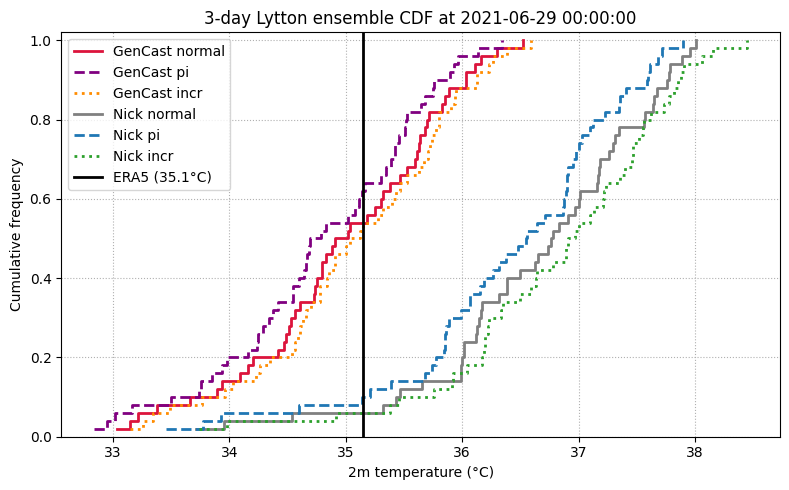

In [ ]:
gencast_init = pd.Timestamp("2021-06-26T00:00:00")
gencast_init_date = gencast_init.strftime("%Y-%m-%d")

city, city_lat, city_lon = "Lytton", 50.224444, -121.581944
CDF_time = pd.to_datetime("2021-06-29T00:00:00")

era5 = xr.open_dataset(
    "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)
era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                     if k in era5.coords or k in era5.dims})
era5_da = to_celsius(era5["t2m"])
era5_city = lon_adjust(era5_da, city_lat, city_lon)

# -----------------------------
# Nick files
# -----------------------------
nick_paths = {
    "normal": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/oper_pf_2021-06-26.nc",
    "pi":     "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/pi/pnw025/sfc/pf/b2mg_2021-06-26.nc",
    "incr":   "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/pIC/incr/pnw025/sfc/pf/b2mh_2021-06-26.nc",
}

# -----------------------------
# GenCast seed-combined files
# Adjust paths if your normal/pi/incr filenames differ.
# -----------------------------
gencast_seed_paths = {
    "normal": [
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_24ens_1seed_predictions.zarr",
    ],
    "pi": [
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_pi_init_2021-06-26T00_10d_24ens_1seed_predictions.zarr",
    ],
    "incr": [
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-26T00_10d_26ens_0seed_predictions.zarr",
        "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/1x1_incr_init_2021-06-26T00_10d_24ens_1seed_predictions.zarr",
    ],
}

# Load Nick
nick = {}
for variant, path in nick_paths.items():
    ds = xr.open_dataset(path, engine="netcdf4")
    ds = ds.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                    if k in ds.coords or k in ds.dims})
    nick[variant] = ds

# Load GenCast
gencast = {}
for variant, paths in gencast_seed_paths.items():
    gc = combine_seed_ensembles(paths)
    if "batch" in gc.dims:
        gc = gc.squeeze("batch")
    gc = gc.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                     if k in gc.coords or k in gc.dims})
    gencast[variant] = gc

# Build city series
nick_city = {}
for variant in nick:
    nick_da = to_celsius(nick[variant]["t2m"])
    nick_city[variant] = lon_adjust(nick_da, city_lat, city_lon)

gencast_city = {}
for variant in gencast:
    gc_da = to_celsius(gencast[variant]["2m_temperature"]).assign_coords(
        time=pd.to_datetime(gencast_init) + gencast[variant]["time"]
    )
    gencast_city[variant] = lon_adjust(gc_da, city_lat, city_lon)

# Choose the valid time
era5_truth = float(era5_city.sel(time=CDF_time, method="nearest").values)

# Nick normal is commented out by request
#nick_variants_to_use = ["pi", "incr"]
nick_variants_to_use = ["normal", "pi", "incr"]

gencast_variants_to_use = ["normal", "pi", "incr"]

# -----------------------------
# Plot CDFs
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

nick_results = {}
gencast_results = {}

nick_styles = {
    "normal": dict(linestyle="-", color="gray"),
    "pi": dict(linestyle="--", color="tab:blue"),
    "incr": dict(linestyle=":", color="tab:green"),
}

gencast_styles = {
    "normal": dict(linestyle="-", color="crimson"),
    "pi": dict(linestyle="--", color="purple"),
    "incr": dict(linestyle=":", color="darkorange"),
}

for variant in gencast_variants_to_use:
    ens = gencast_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
    x = np.sort(ens[np.isfinite(ens)])
    y = np.arange(1, len(x) + 1) / len(x)

    gencast_results[variant] = {
        "x": x,
        "y": y,
        "crps": crps_calculation(x, era5_truth),
        "closest": closest_member(gencast_city[variant], era5_truth, CDF_time, ens_dim="number", label=f"GenCast {variant}"),
        "coolest": coolest_member(gencast_city[variant], CDF_time, ens_dim="number", label=f"GenCast {variant}"),
    }

    ax.step(
        x, y, where="post",
        linewidth=2,
        label=f"GenCast {variant}",
        **gencast_styles[variant]
    )

for variant in nick_variants_to_use:
    ens = nick_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
    x = np.sort(ens[np.isfinite(ens)])
    y = np.arange(1, len(x) + 1) / len(x)

    nick_results[variant] = {
        "x": x,
        "y": y,
        "crps": crps_calculation(x, era5_truth),
        "closest": closest_member(nick_city[variant], era5_truth, CDF_time, ens_dim="number", label=f"Nick {variant}"),
        "coolest": coolest_member(nick_city[variant], CDF_time, ens_dim="number", label=f"Nick {variant}"),
    }

    ax.step(
        x, y, where="post",
        linewidth=2,
        label=f"Nick {variant}",
        **nick_styles[variant]
    )

ax.axvline(
    era5_truth,
    color="black",
    linewidth=2,
    label=f"ERA5 ({era5_truth:.1f}°C)"
)

ax.set_xlabel("2m temperature (°C)")
ax.set_ylabel("Cumulative frequency")
ax.set_title(f"3-day {city} ensemble CDF at {CDF_time}")
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle=":")
ax.legend()
plt.tight_layout()
plt.show()

/tmp/user/28413/ipykernel_2379232/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/tmp/user/28413/ipykernel_2379232/138476893.py:27: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  return xr.concat(datasets, dim="sample").sortby("sample")
/t

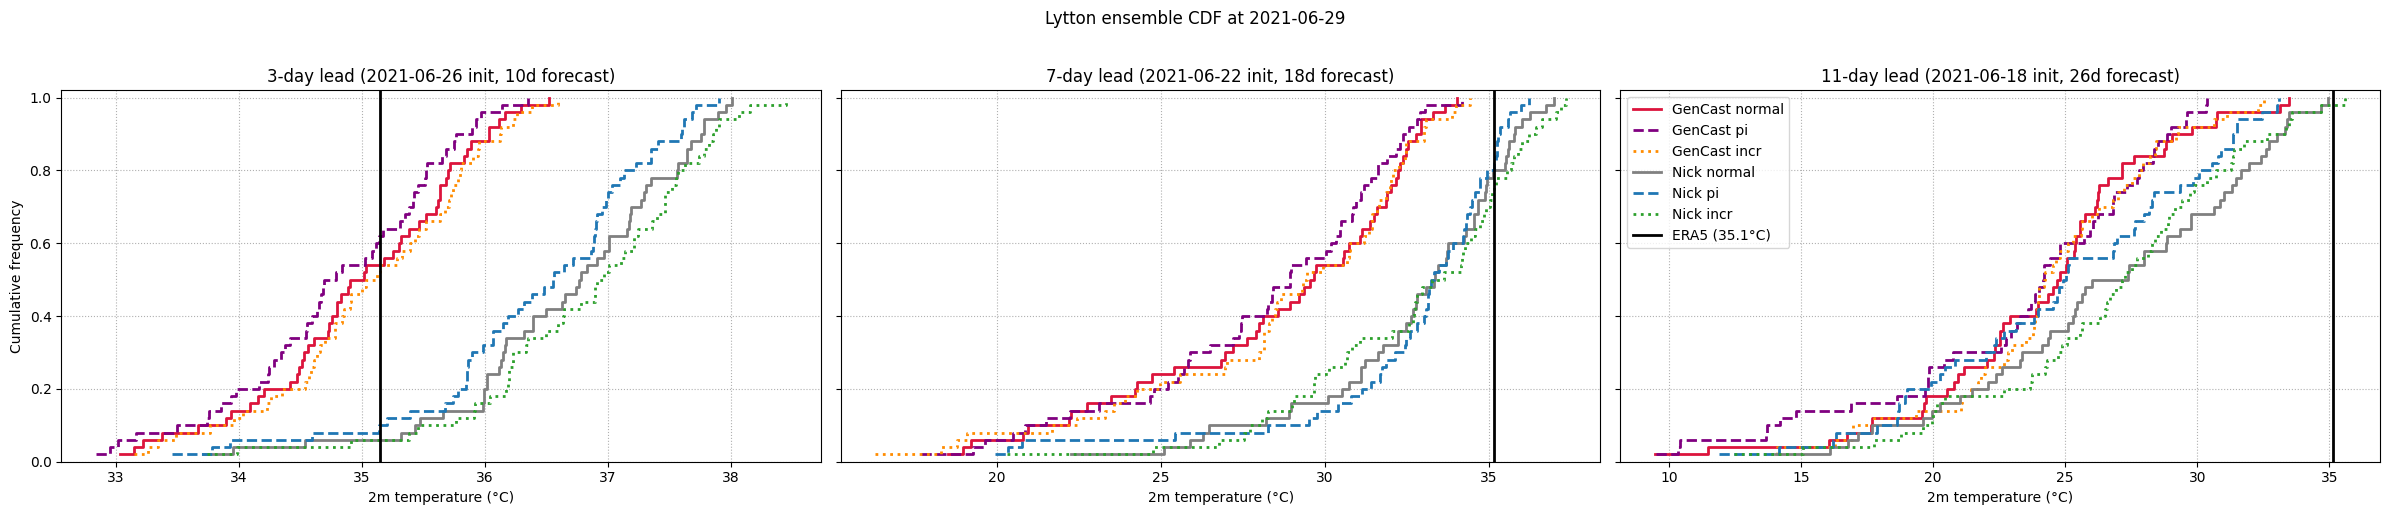

In [6]:
city, city_lat, city_lon = "Lytton", 50.224444, -121.581944
CDF_time = pd.to_datetime("2021-06-29T00:00:00")

# Lead-time cases: init date -> lead days

era5 = xr.open_dataset(
    "/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/era5/pnw025/sfc/2021.nc",
    engine="netcdf4"
)
era5 = era5.rename({k: v for k, v in {"lat": "latitude", "lon": "longitude", "sample": "number"}.items()
                     if k in era5.coords or k in era5.dims})
era5_da = to_celsius(era5["t2m"])
era5_city = lon_adjust(era5_da, city_lat, city_lon)

cases = [
{"lead_days": 3, "init": pd.Timestamp("2021-06-26T00:00:00"), "forecast_steps": 10},
{"lead_days": 7, "init": pd.Timestamp("2021-06-22T00:00:00"), "forecast_steps": 18},
{"lead_days": 11, "init": pd.Timestamp("2021-06-18T00:00:00"), "forecast_steps": 26},
]

nick_styles = {
"normal": dict(linestyle="-", color="gray"),
"pi": dict(linestyle="--", color="tab:blue"),
"incr": dict(linestyle=":", color="tab:green"),
}

gencast_styles = {
"normal": dict(linestyle="-", color="crimson"),
"pi": dict(linestyle="--", color="purple"),
"incr": dict(linestyle=":", color="darkorange"),
}

nick_variants_to_use = ["normal", "pi", "incr"]
gencast_variants_to_use = ["normal", "pi", "incr"]


fig, axes = plt.subplots(1, 3, figsize=(24, 5), sharey=True)

for ax, case in zip(axes, cases):
    init_date = case["init"]
    lead_days = case["lead_days"]
    forecast_steps = case["forecast_steps"]

    # You need these loaded inside the loop for each init date
    nick_city = load_nick_city_series(init_date)
    gencast_city = load_gencast_city_series(init_date, forecast_steps)

    era5_truth = float(era5_city.sel(time=CDF_time, method="nearest").values)

    # Plot GenCast
    for variant in gencast_variants_to_use:
        ens = gencast_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
        ens = ens[np.isfinite(ens)]
        x = np.sort(ens)
        y = np.arange(1, len(x) + 1) / len(x)

        ax.step(
            x, y, where="post",
            linewidth=2,
            label=f"GenCast {variant}",
            **gencast_styles[variant]
        )

    # Plot Nick
    for variant in nick_variants_to_use:
        ens = nick_city[variant].sel(time=CDF_time, method="nearest").dropna("number").values.astype(float)
        ens = ens[np.isfinite(ens)]
        x = np.sort(ens)
        y = np.arange(1, len(x) + 1) / len(x)

        ax.step(
            x, y, where="post",
            linewidth=2,
            label=f"Nick {variant}",
            **nick_styles[variant]
        )

    # Truth line
    ax.axvline(
        era5_truth,
        color="black",
        linewidth=2,
        label=f"ERA5 ({era5_truth:.1f}°C)"
    )

    ax.set_xlabel("2m temperature (°C)")
    ax.set_title(f"{lead_days}-day lead ({init_date.strftime('%Y-%m-%d')} init, {forecast_steps}d forecast)")
    ax.set_ylim(0, 1.02)
    ax.grid(True, linestyle=":")

axes[0].set_ylabel("Cumulative frequency")
axes[-1].legend(loc="best")
fig.suptitle(f"{city} ensemble CDF at {CDF_time.strftime('%Y-%m-%d')}", y=1.02)
plt.tight_layout()
plt.show()